# FPS, задержка и память моделей

[Обзор последних замеров всех моделей](fps_review.ipynb) объединяет результаты разных запусков.

Сравнение включённых моделей через общий `Predictor`: CPU/CUDA, batch=1,
прогрев и отдельные процессы. [Подробный протокол и варианты измерений](scripts/benchmark/README.md).
Синтетический поток не подтверждает качество реального видео. Полный конвейер
защиты растений и HSV здесь не измеряется. Для замеров до обучения используются исходные предобученные веса.

**Direct и stream измеряют разные нагрузки.** В обоих случаях выполняется одно
синхронное предсказание за раз. Direct использует готовые массивы в RAM; stream
добавляет копирование, очередь и ожидание производителя. Это не `stream=True`
Ultralytics и не CUDA streams, поэтому stream не обязан быть быстрее.

**Разбор YOLO26n от 24.11.2026:** direct = 147.04 FPS, stream = 125.28 FPS,
но при запросе 300 FPS источник фактически выдавал только 128.21 FPS.
Локальная проверка выявила грубое ожидание `Event.wait`: около 15.6 мс вместо
3.33 мс, затем кадры поступали пачками. В `core.py` ожидание заменено на
`time.sleep` с проверкой дедлайна; сохранённые ниже результаты относятся
к обученным весам и старому таймеру. Подробности — в разделе README
«Почему stream может быть медленнее direct». Перезапустите kernel и повторите
оба режима в новые каталоги; сравнивайте также `generation_fps`, а не только
заданный `input_fps`. Проверка таймера без модели не подтверждает новый GPU FPS.


In [1]:
from pathlib import Path
import sys

# Поддерживаются запуск из корня репозитория и из manual_notebooks.
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "scripts" / "common.py").is_file() else Path.cwd() / "manual_notebooks"
if not (NOTEBOOK_DIR / "scripts" / "common.py").is_file():
    raise RuntimeError("Open this notebook from the repository root or manual_notebooks")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from scripts import common as cmn, weight as wght
from scripts.workflows import enabled_specs
from scripts.benchmark import BenchmarkConfig, run_benchmarks, load_measurement_runs, select_images
from scripts.benchmark.plots import summary_table, configuration_table, plot_benchmarks, plot_fps_over_time, plot_latency_over_time, plot_series


## Выбор моделей и подготовка исходных весов

Выберите модели в `cmn.MODELS` перед проверкой весов. Как и в `models_training.ipynb`, менеджер переиспользует файлы из `weights/original/` и скачивает недостающие. Оба режима получают пути, возвращённые менеджером.


In [ ]:
# При необходимости измените выбор до проверки и скачивания.
# cmn.MODELS["rtmdet-tiny"] = True
# cmn.MODELS["rf-detr-m"] = True
wght.inspect_weights()


In [ ]:
CHECKPOINTS = wght.download_weights(return_paths=True)
# Для обученного RTMDet укажите пару конкретного запуска:
# CHECKPOINTS["rtmdet-tiny"] = run.best_artifacts


## Конфигурация измерений

Для скрининга выбираются 24 изображения из train.txt мигрированного датасета с фиксированным seed.
Это воспроизводимая выборка, но её покрытие освещения, плотности растений и размеров
нужно проверить отдельно. Для подготовленного списка задайте IMAGE_COUNT = None.
Относительные пути считаются от каталога списка; test и исторические 110 изображений
автоматически не используются. Список, порядок и SHA-256 сохраняются для каждого запуска.
Изображения читаются до измерения, затем циклически используются в заданном порядке.
Все изображения проходят прогрев хотя бы один раз. TORCH_NUM_THREADS фиксирует
число intra-op потоков PyTorch; inter-op = 1. Потоки других библиотек не ограничиваются.


In [ ]:
IMAGE_LIST = cmn.DATASET_PATH / "train.txt"
IMAGE_COUNT = 24  # None — весь явно подготовленный список.
IMAGE_SEED = 20261028
IMAGE_PATHS = select_images(IMAGE_LIST, count=IMAGE_COUNT, seed=IMAGE_SEED)
# Для smoke test можно явно задать IMAGE_PATHS = [путь_к_одному_изображению].
# DEVICES = ["cpu"]  # Например: ["cpu", "cuda:0"].
DEVICES = ["cuda:0"]
PREDICTION_OPTIONS = {
    spec.id: ({"imgsz": 640, "conf": 0.25, "rect": True}
              if spec.backend == "ultralytics" else {"conf": 0.25})
    for spec in enabled_specs()
}
# RF-DETR использует разрешение checkpoint; несовместимый imgsz вызовет ошибку.
PROMPTS = {}  # JSON-совместимые подсказки для моделей, которым они нужны.
RUN_NOTES = ""  # Оборудование, режим питания, внешние ограничения.

WARMUP_FRAMES = 30
MEASUREMENT_SECONDS = 30
INPUT_RATES = (300,)
ORDER_SEED = 20261028
MEMORY_INTERVAL_SECONDS = 0.01
MEMORY_IMAGE_PASSES = 2
TORCH_NUM_THREADS = None  # Одинаковое значение для всех моделей; None — штатное значение SDK.
OUTPUT_ROOT = cmn.ROOT / "experiments" / "benchmarks"

for spec in enabled_specs():
    print(spec.id, spec.backend, CHECKPOINTS[spec.id], spec.unavailable_reason("predict") or "Ready for preflight")


## Прямое измерение

Запустите следующую ячейку, когда нужно измерить direct inference.
Поток запускается собственной ячейкой ниже. Флагов включения нет.
Для каждой пары модель/устройство выполняется один замер длительностью
`MEASUREMENT_SECONDS` в отдельном процессе. Загрузка, прогрев и проход памяти
занимают дополнительное время. Для smoke test достаточно одного изображения,
MEMORY_IMAGE_PASSES = 1, двух кадров прогрева и одной секунды измерения.

Перед окном FPS отдельный проход памяти обрабатывает каждое изображение
MEMORY_IMAGE_PASSES раз без очереди и без накопления записей кадров/отсчётов.
Поля probe_* относятся к этому одинаковому direct-набору нагрузки даже в stream-запуске.
Старые поля памяти относятся к окну FPS и включают память накопленных записей.
Пик загрузки и холодного старта по-прежнему не измеряется.

Прогрев выполняется перед каждым окном с теми же параметрами. Каждый завершённый
замер сразу сохраняется вместе с задержками, памятью и окружением.
Путь к каталогу и worker.log выводится до начала работы.

Индикатор считает завершённые замеры и показывает модель, устройство, режим,
стадию и время стадии. Интерфейс обновляется раз в секунду в родительском
процессе; внутри измеряемого цикла обновлений прогресса нет. Время стадии
служит подсказкой и не используется для расчёта метрик.


In [3]:
config = BenchmarkConfig(
    warmup_frames=WARMUP_FRAMES, duration_s=MEASUREMENT_SECONDS,
    input_rates=INPUT_RATES,
    direct=True, stream=False,
    seed=ORDER_SEED, memory_interval_s=MEMORY_INTERVAL_SECONDS,
    memory_passes=MEMORY_IMAGE_PASSES, torch_num_threads=TORCH_NUM_THREADS,
)
DIRECT_RESULT_DIRECTORY = run_benchmarks(
    CHECKPOINTS, IMAGE_PATHS, devices=DEVICES, config=config,
    prediction_options=PREDICTION_OPTIONS, prompts=PROMPTS,
    output_root=OUTPUT_ROOT, notes=RUN_NOTES,
)
RESULT_DIRECTORY = DIRECT_RESULT_DIRECTORY
print(f"Completed: {RESULT_DIRECTORY}")


Benchmark directory: C:\Users\natsusa_aki\academic\tobacco-article\experiments\benchmarks\20261124T112202Z-f687b1c3


c:\Users\natsusa_aki\academic\tobacco-article\.venv-notebooks\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Benchmarks:   0%|          | 0/1 [00:00]

Running yolo26n on cuda:0; log: C:\Users\natsusa_aki\academic\tobacco-article\experiments\benchmarks\20261124T112202Z-f687b1c3\0000-yolo26n-cuda-0\worker.log


Benchmarks: 100%|██████████| 1/1 [00:34, Completed]                                  

Completed: C:\Users\natsusa_aki\academic\tobacco-article\experiments\benchmarks\20261124T112202Z-f687b1c3


## Синтетический поток

Запустите эту ячейку для sweep по `INPUT_RATES`; direct-ячейку запускать не обязательно.
Длительность: `MEASUREMENT_SECONDS × len(INPUT_RATES)` на пару
модель/устройство плюс загрузка, прогрев и проход памяти для каждого замера.
При 30 FPS на входе processing FPS ограничен подачей: сравнивайте запас
пропускной способности по direct, а поток — по задержке и пропускам. При запуске всех ячеек выполняются оба режима.


In [4]:
config = BenchmarkConfig(
    warmup_frames=WARMUP_FRAMES, duration_s=MEASUREMENT_SECONDS,
    input_rates=INPUT_RATES,
    direct=False, stream=True,
    seed=ORDER_SEED, memory_interval_s=MEMORY_INTERVAL_SECONDS,
    memory_passes=MEMORY_IMAGE_PASSES, torch_num_threads=TORCH_NUM_THREADS,
)
STREAM_RESULT_DIRECTORY = run_benchmarks(
    CHECKPOINTS, IMAGE_PATHS, devices=DEVICES, config=config,
    prediction_options=PREDICTION_OPTIONS, prompts=PROMPTS,
    output_root=OUTPUT_ROOT, notes=RUN_NOTES,
)
RESULT_DIRECTORY = STREAM_RESULT_DIRECTORY
print(f"Completed: {RESULT_DIRECTORY}")


Benchmark directory: C:\Users\natsusa_aki\academic\tobacco-article\experiments\benchmarks\20261124T112236Z-05854e86


Benchmarks:   0%|          | 0/1 [00:00]

Running yolo26n on cuda:0; log: C:\Users\natsusa_aki\academic\tobacco-article\experiments\benchmarks\20261124T112236Z-05854e86\0000-yolo26n-cuda-0\worker.log


Benchmarks: 100%|██████████| 1/1 [00:34, Completed]                                          

Completed: C:\Users\natsusa_aki\academic\tobacco-article\experiments\benchmarks\20261124T112236Z-05854e86


## Таблица и графики без повторного inference

Задайте `SAVED_RESULT_DIRECTORY`, чтобы открыть прошлый или прерванный запуск.
По умолчанию отображается последний выполненный режим. Можно указать
`DIRECT_RESULT_DIRECTORY` или `STREAM_RESULT_DIRECTORY` для выбора режима.
Processing FPS — число завершённых кадров / фактическая длительность окна.
Frame latency включает копирование и очередь, поэтому её обратная величина не FPS.

RSS — память всего worker, выборочный пик с интервалом 10 мс. CUDA allocated/reserved —
отдельные показатели аллокатора PyTorch после прогрева, не полная VRAM устройства.
Их нельзя складывать с RAM или друг с другом. На CPU CUDA-поля отсутствуют (`null`).
Сначала показаны настройки SDK, затем метрики каждого замера.
configured_input_size — настройка SDK, а не измеренная форма тензора.
Проверяйте различия разрешения, rect и precision до сравнения архитектур.
Для сравнения памяти используйте probe_*; в stream они не включают очередь.
Поля без probe_ остаются диагностикой памяти окна FPS с очередью и записями.
В старых результатах probe_* отсутствуют и не восстанавливаются из RSS.


,model_id,device,backend,input_rates,image_count,source_shapes,configured_input_size,rect,precision,actual_tensor_shape,torch_threads,prediction_options,status
0,yolo26n,cuda:0,ultralytics,[300],24,"[(352, 480, 3)]","[640, 640]",True,float32,None,16,"{'imgsz': 640, 'conf': 0.25, 'rect': True}",completed


,model_id,device,mode,input_fps,processed,elapsed_s,processing_fps,prediction_ms_mean,prediction_ms_median,prediction_ms_p95,...,cuda_reserved_mib_warm,cuda_allocated_mib_peak,cuda_reserved_mib_peak,probe_rss_warm_mib,probe_rss_sampled_peak_mib,probe_cuda_allocated_mib_warm,probe_cuda_reserved_mib_warm,probe_cuda_allocated_mib_peak,probe_cuda_reserved_mib_peak,rss_baseline_mib
0,yolo26n,cuda:0,stream,300,4309,30.004981,143.609487,6.955107,6.8812,7.65324,...,86.0,68.774902,86.0,1620.140625,1620.171875,41.160156,86.0,68.774902,86.0,661.503906


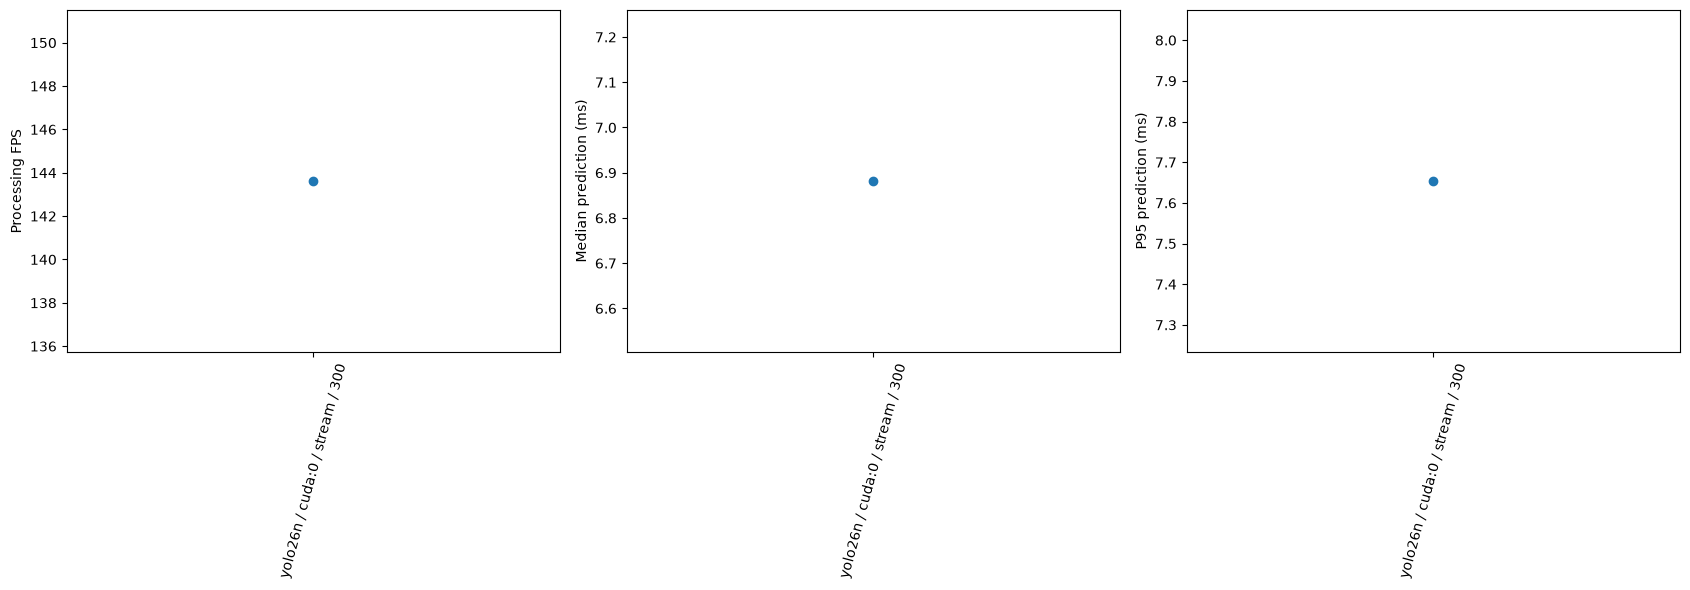

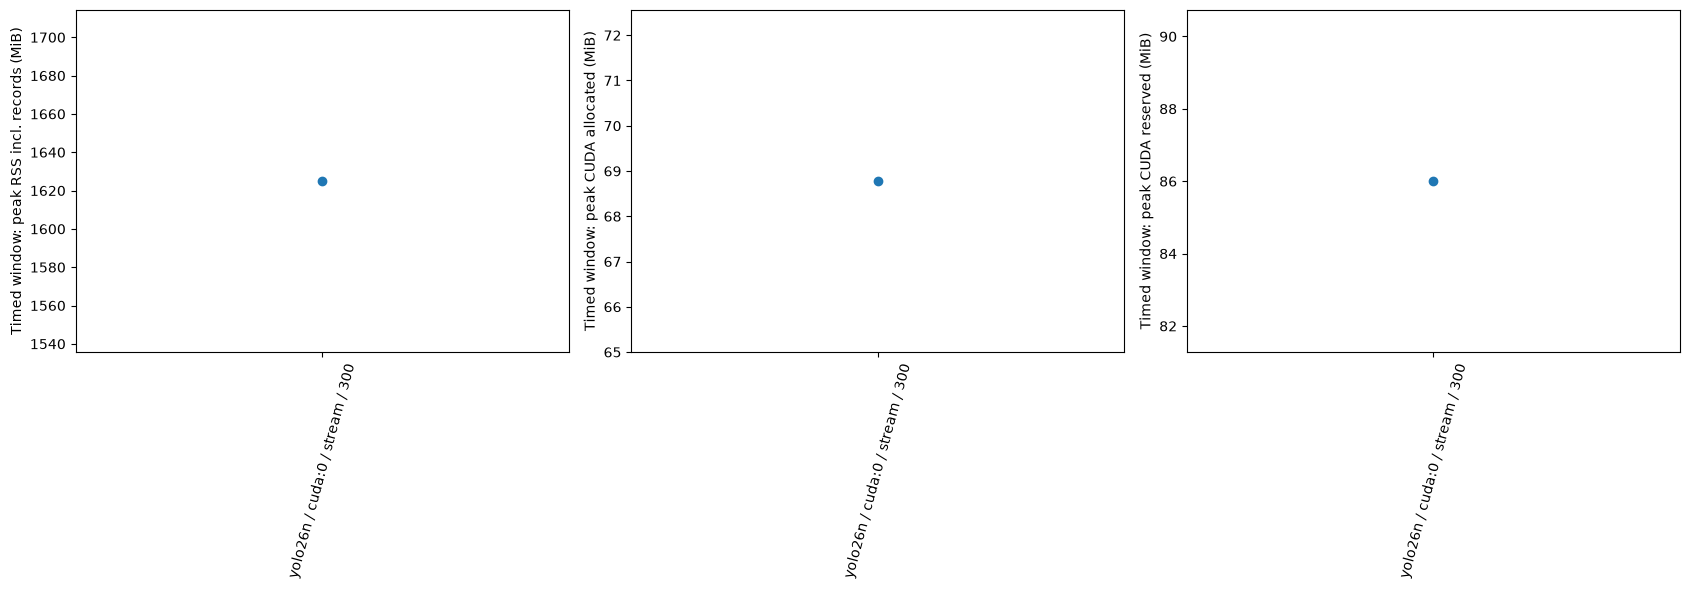

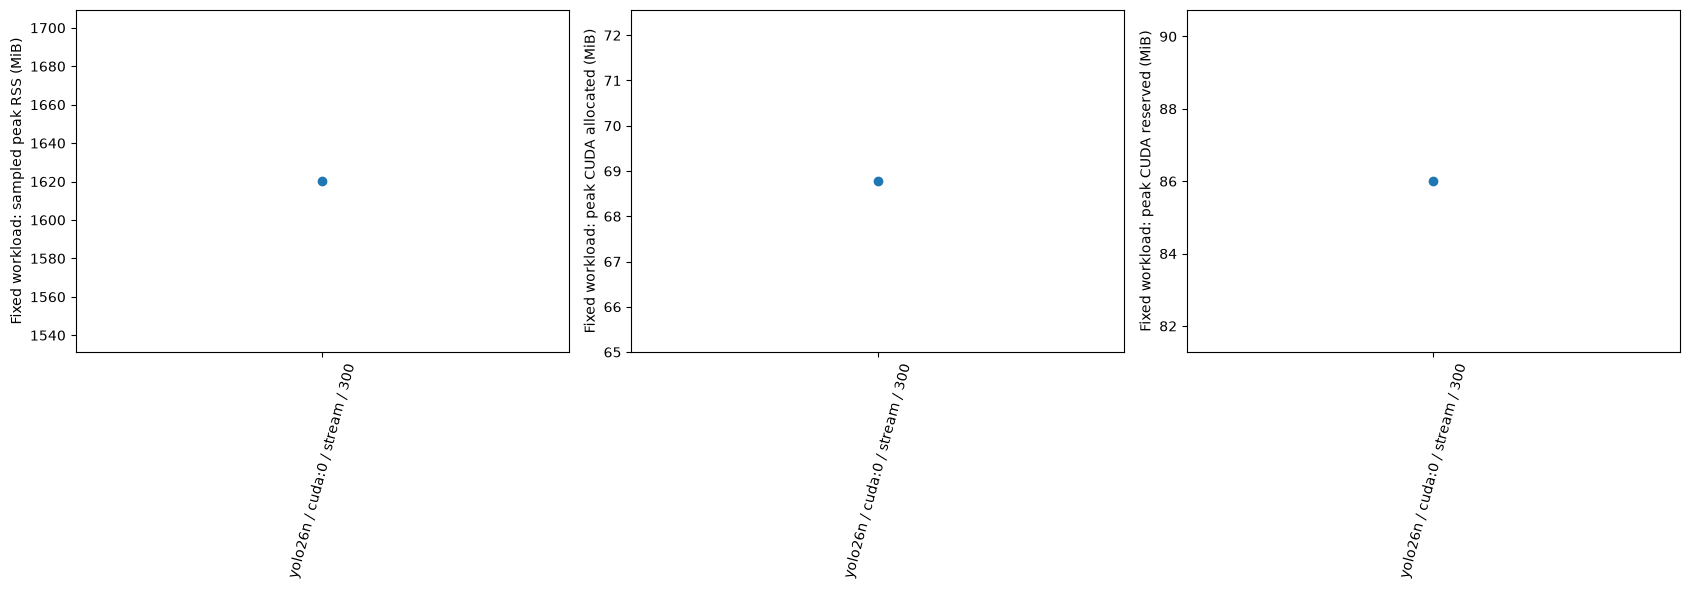

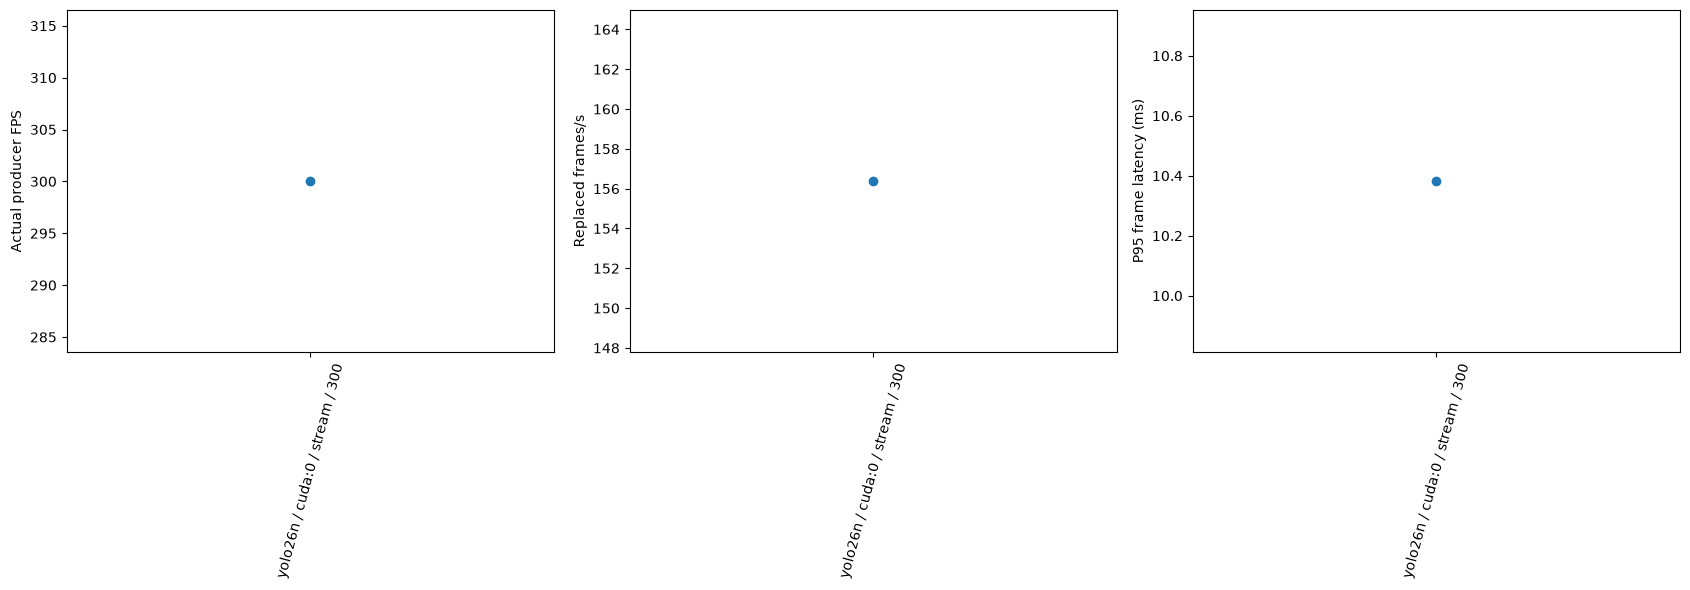

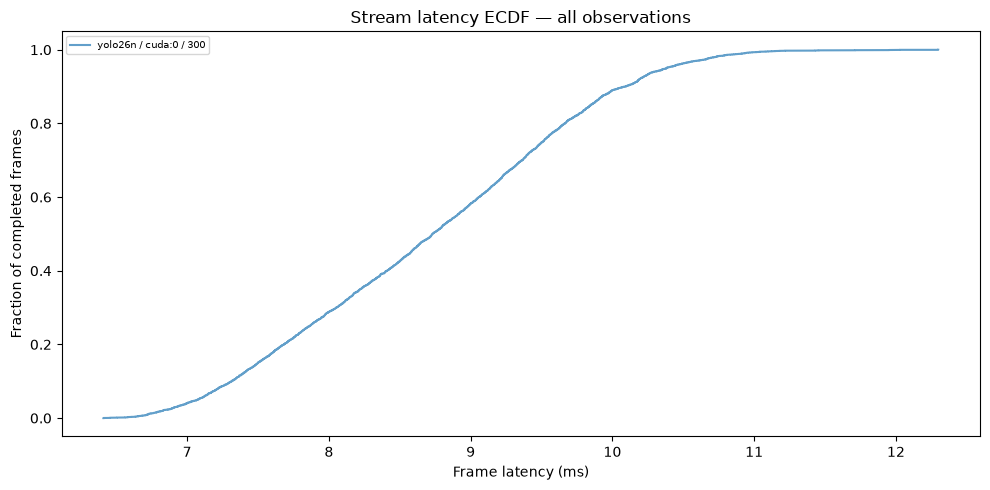

In [5]:
ZERO_BASED_Y = False  # Автомасштаб по данным; True — начинать ось Y с нуля.
SAVED_RESULT_DIRECTORY = None  # Например: OUTPUT_ROOT / "20261121T120000Z-..."
results_path = SAVED_RESULT_DIRECTORY or globals().get("RESULT_DIRECTORY")
runs = load_measurement_runs(results_path) if results_path is not None else []
if results_path is not None:
    from IPython.display import display
    display(configuration_table(results_path))
    display(summary_table(results_path))
    plot_benchmarks(results_path)
else:
    print("Run the benchmark or set SAVED_RESULT_DIRECTORY to an existing results directory.")


## FPS во времени для каждой модели

Отдельная фигура для каждой пары модель/устройство, отдельная панель для каждого
режима/входной частоты. По X — секунды после прогрева, для `binned` по Y — число завершённых
кадров в окне / длительность окна.
Последнее неполное окно делится на его фактическую длительность, пустые окна дают 0 FPS.
Изменяйте `FPS_BIN_SECONDS` для более подробного или сглаженного отображения.
При `FPS_KIND = "instantaneous"` показан обратный интервал между соседними завершениями кадров.
Эта ячейка читает сохранённые результаты и не запускает inference.


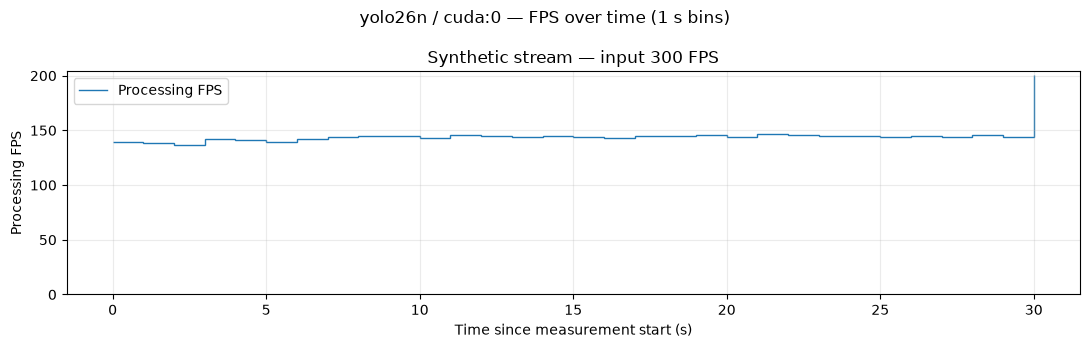

In [6]:
FPS_KIND = "binned"  # "binned" или "instantaneous"
FPS_BIN_SECONDS = 1.0  # Ширина окна для binned.
if results_path is not None:
    plot_fps_over_time(runs, kind=FPS_KIND, bin_seconds=FPS_BIN_SECONDS, zero_based_y=ZERO_BASED_Y)
else:
    print("Select a results directory in the table cell above.")


## Задержка (мс) во времени для каждой модели

По X — время завершения кадра в секундах после начала измерения, по Y — задержка
в миллисекундах. Сплошная линия — время предсказания; для синтетического потока
пунктиром дополнительно показана задержка кадра с копированием и очередью.
Все наблюдения сохранены, без фильтрации выбросов
и усреднения. Используются те же сохранённые результаты, что и для FPS.


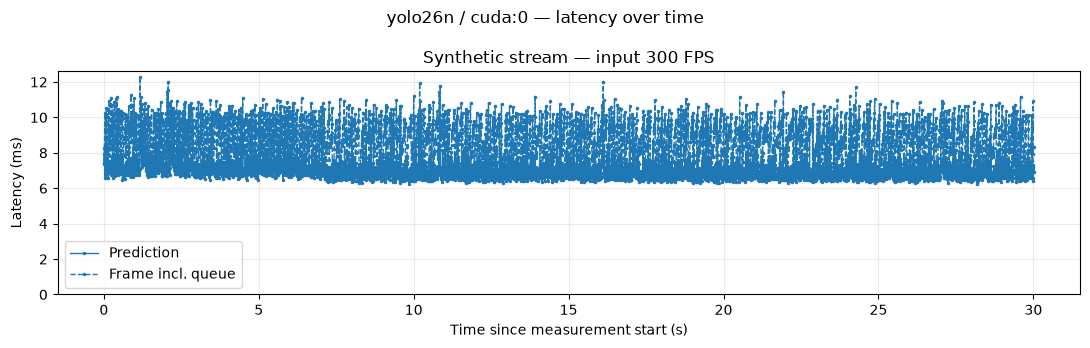

In [7]:
if results_path is not None:
    plot_latency_over_time(runs, zero_based_y=ZERO_BASED_Y)
else:
    print("Select a results directory in the table cell above.")


## Работа с отдельным замером: срез и фильтрация

`runs` содержит отдельный `MeasurementRun` для каждой комбинации модели, устройства,
режима и запуска. Выберите `RUN_INDEX` по списку ниже. Времена заданы в секундах
от начала исходного замера; `slice(5, 10)` сохраняет эту шкалу.
Срез включает левую границу и исключает правую, кроме конца исходного замера.

`processing_fps` — число завершений / длительность выбранного окна.
`fps(kind="binned")` считает завершения по окнам; `fps(kind="instantaneous")`
использует обратный интервал между соседними завершениями внутри среза.
Это не обратная задержка кадра. Для пустого среза оконный FPS равен нулю,
а для менее двух завершений мгновенный ряд пуст.

`filter_outliers` создаёт новый ряд с маской исключения. Исходные времена,
значения и пропускная способность замера не меняются; исключённые точки дают
разрывы на графике. IQR вычисляется по ещё включённым значениям; при нулевом IQR
остаются только значения между Q1 и Q3. Фильтрация нужна для исследования графика,
а сохранённые сводки продолжают использовать все наблюдения.

Сначала делайте срез замера, затем вычисляйте FPS, чтобы пересчитать крайние окна.
Срез готового ряда (`series.slice(...)`) только обрезает отображение:
значения частично видимых интервалов остаются прежними.

Последний график также показывает direct FPS (исходный и после IQR-фильтра)
для той же модели и устройства. Используется `DIRECT_RESULT_DIRECTORY` текущей
сессии; для прошлых результатов задайте `SAVED_DIRECT_RESULT_DIRECTORY`.
Если путь не задан, direct-замер ищется среди уже загруженных `runs`.
При нескольких совпадениях берётся первый замер. Новое предсказание не запускается.
Оба режима используют одинаковые настройки фильтра; для direct берётся пересечение
с выбранным временным окном. Шкала X означает секунды от начала каждого отдельного
замера после прогрева, а не одновременную запись двух режимов.


0: yolo26n / cuda:0 / stream / input 300 FPS / 30.00 s
Selected window: 5–20 s; processing FPS: 144.067


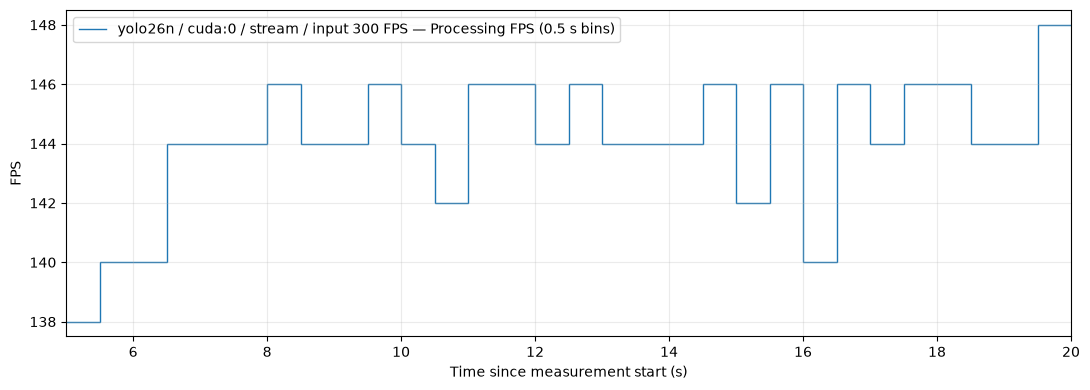

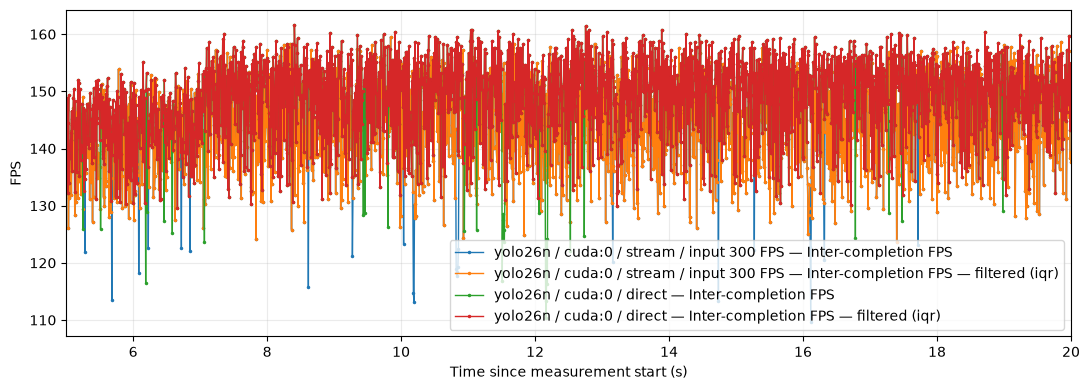

In [8]:
for index, candidate in enumerate(runs):
    print(f"{index}: {candidate.label} / {candidate.duration_s:.2f} s")

RUN_INDEX = 0
SAVED_DIRECT_RESULT_DIRECTORY = None  # Каталог direct-замера из предыдущей сессии.
SLICE_START_SECONDS = 5.0
SLICE_END_SECONDS = 20.0

if runs:
    run = runs[RUN_INDEX]
    # Для короткого smoke test используем весь замер.
    selected = (run.slice(SLICE_START_SECONDS, SLICE_END_SECONDS)
                if run.end_s >= SLICE_END_SECONDS else run)
    print(f"Selected window: {selected.start_s:g}–{selected.end_s:g} s; "
          f"processing FPS: {selected.processing_fps:.3f}")

    binned = selected.fps(kind="binned", bin_seconds=0.5)
    instantaneous = selected.fps(kind="instantaneous")
    filtered = instantaneous.filter_outliers(method="iqr", factor=1.5)
    # Альтернатива с явными границами:
    # filtered = instantaneous.filter_outliers(method="bounds", minimum=1, maximum=100)
    plot_series(binned)
    comparison = [instantaneous, filtered]
    if selected.mode != "direct":
        direct_path = SAVED_DIRECT_RESULT_DIRECTORY or globals().get("DIRECT_RESULT_DIRECTORY")
        direct_runs = load_measurement_runs(direct_path) if direct_path is not None else runs
        matching_direct = [candidate for candidate in direct_runs
                           if candidate.mode == "direct"
                           and candidate.model_id == selected.model_id
                           and candidate.device == selected.device]
        if matching_direct:
            direct = matching_direct[0]
            start = max(selected.start_s, direct.start_s)
            end = min(selected.end_s, direct.end_s)
            if start < end:
                direct_fps = direct.slice(start, end).fps(kind="instantaneous")
                comparison.extend([direct_fps, direct_fps.filter_outliers(method="iqr", factor=1.5)])
                if (start, end) != (selected.start_s, selected.end_s):
                    print(f"Direct run covers only {start:g}–{end:g} s of the selected window.")
            else:
                print("Direct run has no overlap with the selected time window.")
        else:
            print("No matching direct run found. Set SAVED_DIRECT_RESULT_DIRECTORY "
                  "to compare the same model and device.")
    plot_series(comparison)
    # Можно передать сам замер или его срез непосредственно в plot_series(selected).
    # Задержки также доступны: plot_series(selected.latency()).
else:
    print("Select a results directory in the table cell above.")
